# USCityURL Dataset Creation

## Goal

This notebook tests each unique official municipality homepage once and records whether it returned a usable response. It checks only the homepage and does not crawl internal pages or collect documents.

## Saved datasets

- **Access audit:** `datasets_USCityPipeline/USCityURL_audit.csv`  
  One row per unique tested homepage with its access response, result category, and technical error details.
- **Pipeline input:** `datasets_USCityPipeline/USCityURL_Pipeline.csv`  
  One row per municipality whose audited homepage returned successful HTML.

Every full run performs a new website audit, replaces both saved CSV files, and builds the pipeline-ready file from the new audit.

## 1. Set up the audit

This section loads the tools, sets a request timeout, and chooses the number of parallel workers. The limits keep the audit focused on one lightweight homepage check per unique URL.

In [1]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from time import perf_counter
from urllib.parse import urldefrag, urlsplit, urlunsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

USCITYURL_CSV = "https://raw.githubusercontent.com/caimeng2/UScityURL/master/UScityURL.csv"
AUDIT_CSV = Path("datasets_USCityPipeline/USCityURL_audit.csv")
PIPELINE_CSV = Path("datasets_USCityPipeline/USCityURL_Pipeline.csv")

MAX_WORKERS = 40
CONNECT_TIMEOUT = 5
READ_TIMEOUT = 10
SAMPLE_BYTES = 65_536

HEADERS = {
    "User-Agent": "CMSE495-USCityURL-Access-Audit/1.0 (educational research)"
}

plt.style.use("seaborn-v0_8-whitegrid")
print(f"Parallel workers: {MAX_WORKERS}")
print(f"Timeout: {CONNECT_TIMEOUT}s to connect and {READ_TIMEOUT}s to read")

Parallel workers: 40
Timeout: 5s to connect and 10s to read


## 2. Load and prepare the website list

The code separates records with no website and checks that the remaining URLs use HTTP or HTTPS. Repeated homepage URLs are tested once so the same site is not contacted unnecessarily.

In [2]:
def normalize_url(value):
    if pd.isna(value) or not str(value).strip():
        return None

    clean_url, _ = urldefrag(str(value).strip())
    parts = urlsplit(clean_url)
    if parts.scheme.lower() not in {"http", "https"} or not parts.netloc:
        return None

    return urlunsplit((
        parts.scheme.lower(),
        parts.netloc.lower(),
        parts.path or "/",
        parts.query,
        "",
    ))


cities = pd.read_csv(USCITYURL_CSV)
cities["normalized_url"] = cities["WEBSITE_URL"].apply(normalize_url)

rows_without_url = int(cities["WEBSITE_URL"].isna().sum())
rows_with_invalid_url = int(
    cities["WEBSITE_URL"].notna().sum() - cities["normalized_url"].notna().sum()
)

sites = (
    cities.loc[cities["normalized_url"].notna(), [
        "GEOID", "MUNICIPALITY", "STATE", "WEBSITE_URL", "normalized_url"
    ]]
    .drop_duplicates("normalized_url")
    .reset_index(drop=True)
)

print(f"USCityURL records: {len(cities):,}")
print(f"Records with no website URL: {rows_without_url:,}")
print(f"Records with an invalid website URL: {rows_with_invalid_url:,}")
print(f"Unique homepages to test: {len(sites):,}")
display(sites.head())

USCityURL records: 19,518
Records with no website URL: 5,795
Records with an invalid website URL: 1
Unique homepages to test: 13,721


,GEOID,MUNICIPALITY,STATE,WEBSITE_URL,normalized_url
0,1600000US3651000,New York,New York,https://www.nyc.gov/,https://www.nyc.gov/
1,1600000US0644000,Los Angeles,California,https://www.lacity.org/,https://www.lacity.org/
2,1600000US1714000,Chicago,Illinois,https://www.chicago.gov/,https://www.chicago.gov/
3,1600000US4835000,Houston,Texas,http://www.houstontx.gov/,http://www.houstontx.gov/
4,1600000US0455000,Phoenix,Arizona,https://www.phoenix.gov/,https://www.phoenix.gov/


## 3. Test each unique homepage

The notebook requests every unique homepage in parallel and replaces the ten-column audit file with the new results. The pipeline-ready file is then rebuilt from this same audit.

When no HTTP response is received, the final URL, status code, and content type stay blank. This can happen because of a connection, DNS, SSL, or timeout failure; the response-time field still records how long the failed attempt took.

In [3]:
def classify_response(status_code, is_html):
    if 200 <= status_code < 300:
        return "Accessible HTML" if is_html else "Accessible non-HTML"
    if 300 <= status_code < 400:
        return "Redirect problem (3xx)"
    if status_code == 401:
        return "Unauthorized (401)"
    if status_code == 403:
        return "Forbidden (403)"
    if status_code in {404, 410}:
        return "Not found (404/410)"
    if status_code == 429:
        return "Rate limited (429)"
    if 400 <= status_code < 500:
        return "Other client error (4xx)"
    if status_code >= 500:
        return "Server error (5xx)"
    return "Other HTTP response"


def test_homepage(row):
    started = perf_counter()
    result = {
        "geoid": row.GEOID,
        "municipality": row.MUNICIPALITY,
        "state": row.STATE,
        "original_url": row.WEBSITE_URL,
        "normalized_url": row.normalized_url,
        "final_url": None,
        "status_code": None,
        "content_type": None,
        "response_seconds": None,
        "category": None,
        "error_detail": None,
    }

    try:
        with requests.get(
            row.normalized_url,
            headers=HEADERS,
            timeout=(CONNECT_TIMEOUT, READ_TIMEOUT),
            allow_redirects=True,
            stream=True,
        ) as response:
            sample = next(response.iter_content(chunk_size=SAMPLE_BYTES), b"")
            content_type = response.headers.get("Content-Type", "").split(";", 1)[0].lower()
            sample_lower = sample.lower()
            is_html = (
                "html" in content_type
                or b"<html" in sample_lower
                or b"<!doctype html" in sample_lower
            )
            result.update({
                "final_url": response.url,
                "status_code": response.status_code,
                "content_type": content_type or "unknown",
                "category": classify_response(response.status_code, is_html),
            })

    except requests.exceptions.Timeout as error:
        result["category"] = "Timeout"
        result["error_detail"] = str(error)[:300]
    except requests.exceptions.SSLError as error:
        result["category"] = "SSL error"
        result["error_detail"] = str(error)[:300]
    except requests.exceptions.ConnectionError as error:
        result["category"] = "Connection error"
        result["error_detail"] = str(error)[:300]
    except requests.RequestException as error:
        result["category"] = "Other request error"
        result["error_detail"] = str(error)[:300]

    result["response_seconds"] = perf_counter() - started
    return result


audit_started = perf_counter()
results = []

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(test_homepage, row) for row in sites.itertuples(index=False)]
    for completed, future in enumerate(as_completed(futures), start=1):
        results.append(future.result())
        if completed % 500 == 0 or completed == len(futures):
            print(f"Completed {completed:,} of {len(futures):,} homepages")

request_results = (
    pd.DataFrame(results)
    .sort_values("normalized_url")
    .reset_index(drop=True)
)
audit_minutes = (perf_counter() - audit_started) / 60

saved_results = request_results.drop(columns=["original_url"])
AUDIT_CSV.parent.mkdir(parents=True, exist_ok=True)
saved_results.to_csv(AUDIT_CSV, index=False)

print(f"Finished in {audit_minutes:.1f} minutes")
print(f"Saved: {AUDIT_CSV}")
print(f"Saved audit shape: {saved_results.shape[0]:,} rows x {saved_results.shape[1]} columns")

results_df = saved_results.copy()


Completed 500 of 13,721 homepages
Completed 1,000 of 13,721 homepages
Completed 1,500 of 13,721 homepages
Completed 2,000 of 13,721 homepages
Completed 2,500 of 13,721 homepages
Completed 3,000 of 13,721 homepages
Completed 3,500 of 13,721 homepages
Completed 4,000 of 13,721 homepages
Completed 4,500 of 13,721 homepages
Completed 5,000 of 13,721 homepages
Completed 5,500 of 13,721 homepages
Completed 6,000 of 13,721 homepages
Completed 6,500 of 13,721 homepages
Completed 7,000 of 13,721 homepages
Completed 7,500 of 13,721 homepages
Completed 8,000 of 13,721 homepages
Completed 8,500 of 13,721 homepages
Completed 9,000 of 13,721 homepages
Completed 9,500 of 13,721 homepages
Completed 10,000 of 13,721 homepages
Completed 10,500 of 13,721 homepages
Completed 11,000 of 13,721 homepages
Completed 11,500 of 13,721 homepages
Completed 12,000 of 13,721 homepages
Completed 12,500 of 13,721 homepages
Completed 13,000 of 13,721 homepages
Completed 13,500 of 13,721 homepages
Completed 13,721 of 13

## 4. Summarize the homepage results

The table reports both counts and percentages of unique homepages. Permission blocks are kept separate from timeouts, missing pages, server failures, and successful pages that return something other than HTML.

In [4]:
category_order = [
    "Accessible HTML",
    "Accessible non-HTML",
    "Forbidden (403)",
    "Unauthorized (401)",
    "Rate limited (429)",
    "Not found (404/410)",
    "Other client error (4xx)",
    "Server error (5xx)",
    "Redirect problem (3xx)",
    "Timeout",
    "SSL error",
    "Connection error",
    "Other request error",
    "Other HTTP response",
]

category_summary = (
    results_df["category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
    .rename_axis("category")
    .reset_index(name="homepages")
)
category_summary = category_summary.loc[category_summary["homepages"] > 0].copy()
category_summary["percent"] = category_summary["homepages"] / len(results_df) * 100

permission_blocked = results_df["category"].isin([
    "Forbidden (403)", "Unauthorized (401)"
]).sum()
accessible_html = results_df["category"].eq("Accessible HTML").sum()
http_response_received = results_df["status_code"].notna().sum()
summary = pd.Series({
    "USCityURL records": len(cities),
    "Records with no website URL": rows_without_url,
    "Unique homepages tested": len(results_df),
    "Homepages returning an HTTP response": int(http_response_received),
    "Accessible HTML homepages": int(accessible_html),
    "Explicit permission blocks (401 or 403)": int(permission_blocked),
}, name="count").to_frame()

display(summary)
display(category_summary.round({"percent": 2}))

,count
USCityURL records,19518
Records with no website URL,5795
Unique homepages tested,13721
Homepages returning an HTTP response,12911
Accessible HTML homepages,11609
Explicit permission blocks (401 or 403),1090


,category,homepages,percent
0,Accessible HTML,11609,84.61
2,Forbidden (403),1087,7.92
3,Unauthorized (401),3,0.02
4,Rate limited (429),2,0.01
5,Not found (404/410),88,0.64
6,Other client error (4xx),14,0.10
7,Server error (5xx),58,0.42
8,Redirect problem (3xx),50,0.36
9,Timeout,132,0.96
10,SSL error,252,1.84


## 5. Plot where homepage access succeeds or fails

The first chart shows the complete outcome breakdown. The second chart shows response times only for homepages that returned an HTTP response, so connection failures are not mixed into the timing distribution.

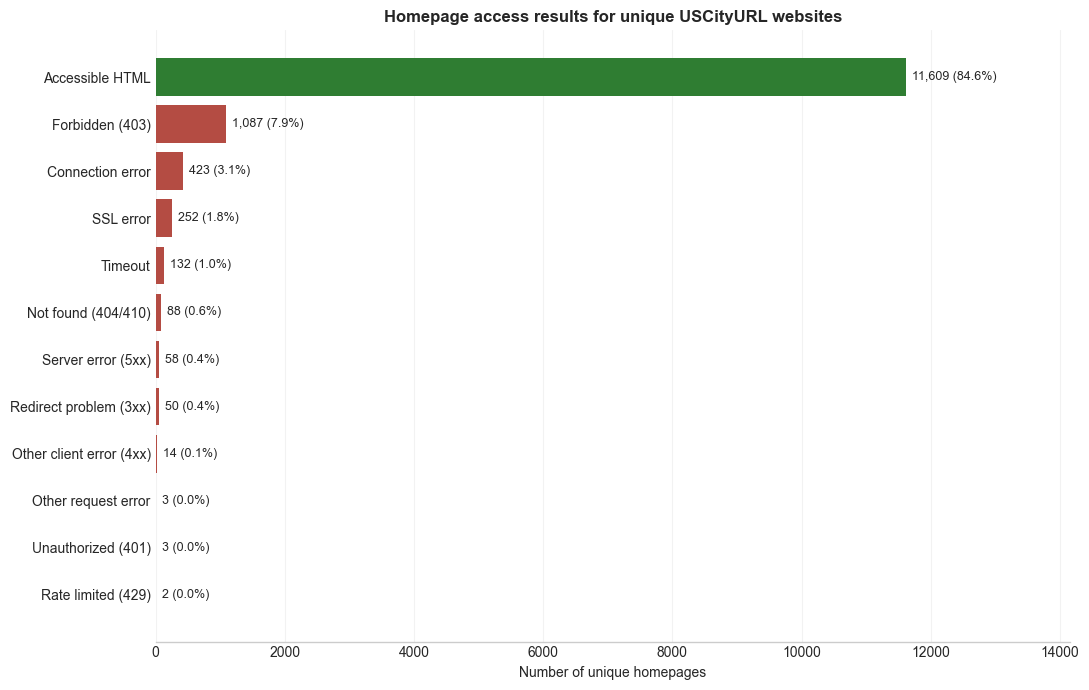

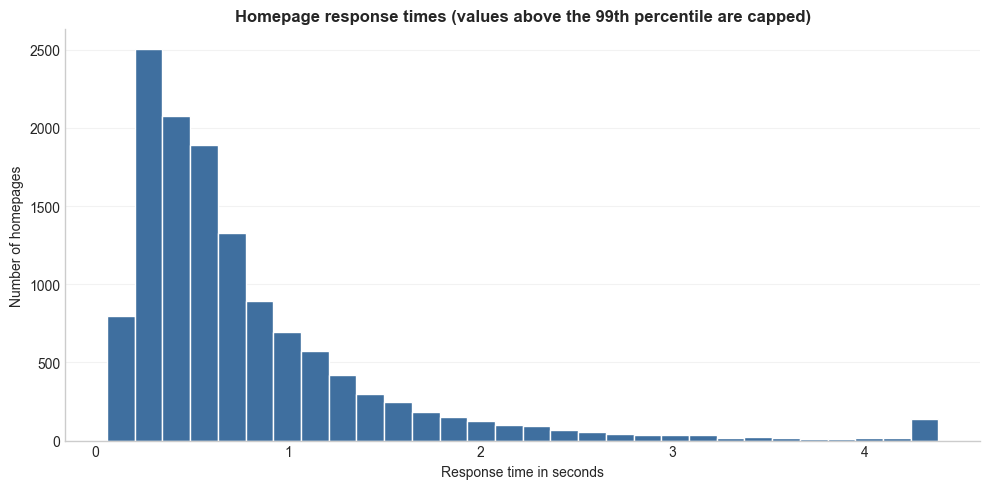

Median response time: 0.57 seconds
95th percentile response time: 2.20 seconds


In [5]:
plot_data = category_summary.sort_values("homepages")

fig, axis = plt.subplots(figsize=(11, 7))
colors = [
    "#2f7d32" if category.startswith("Accessible") else "#b44c43"
    for category in plot_data["category"]
]
bars = axis.barh(plot_data["category"], plot_data["homepages"], color=colors)
axis.set_title("Homepage access results for unique USCityURL websites", fontweight="bold")
axis.set_xlabel("Number of unique homepages")
axis.set_ylabel("")
axis.grid(axis="x", alpha=0.25)
axis.grid(axis="y", visible=False)
axis.spines[["top", "right", "left"]].set_visible(False)

for bar, count, percent in zip(bars, plot_data["homepages"], plot_data["percent"]):
    axis.text(
        bar.get_width() + max(plot_data["homepages"]) * 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({percent:.1f}%)",
        va="center",
        fontsize=9,
    )

axis.set_xlim(0, max(plot_data["homepages"]) * 1.22)
plt.tight_layout()
plt.show()


response_times = results_df.loc[
    results_df["status_code"].notna(), "response_seconds"
].dropna()

upper_limit = response_times.quantile(0.99)
fig, axis = plt.subplots(figsize=(10, 5))
axis.hist(
    response_times.clip(upper=upper_limit),
    bins=30,
    color="#3f6f9f",
    edgecolor="white",
)
axis.set_title("Homepage response times (values above the 99th percentile are capped)", fontweight="bold")
axis.set_xlabel("Response time in seconds")
axis.set_ylabel("Number of homepages")
axis.grid(axis="y", alpha=0.25)
axis.grid(axis="x", visible=False)
axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Median response time: {response_times.median():.2f} seconds")
print(f"95th percentile response time: {response_times.quantile(0.95):.2f} seconds")

## 6. Conclusions

The statements below are generated from this run. They separate explicit permission blocks from technical failures because a timeout, missing page, or connection error does not mean access was forbidden.

In [6]:
tested = len(results_df)
accessible_total = results_df["category"].isin([
    "Accessible HTML", "Accessible non-HTML"
]).sum()
no_http_response = results_df["status_code"].isna().sum()
other_http_errors = tested - accessible_total - permission_blocked - no_http_response

print("Main conclusions")
print(f"- {accessible_total:,} of {tested:,} tested homepages ({accessible_total / tested * 100:.1f}%) returned a successful response.")
print(f"- {accessible_html:,} ({accessible_html / tested * 100:.1f}%) returned accessible HTML.")
print(f"- {permission_blocked:,} ({permission_blocked / tested * 100:.1f}%) explicitly returned 401 or 403 permission errors.")
print(f"- {no_http_response:,} ({no_http_response / tested * 100:.1f}%) did not return an HTTP response during the test.")
print(f"- {other_http_errors:,} ({other_http_errors / tested * 100:.1f}%) returned another HTTP error or redirect problem.")
print(f"- {rows_without_url:,} of {len(cities):,} USCityURL records ({rows_without_url / len(cities) * 100:.1f}%) had no website URL and could not be tested.")
print("- These results are a one-time snapshot. Temporary failures should not be treated as permanent website restrictions.")

Main conclusions
- 11,609 of 13,721 tested homepages (84.6%) returned a successful response.
- 11,609 (84.6%) returned accessible HTML.
- 1,090 (7.9%) explicitly returned 401 or 403 permission errors.
- 810 (5.9%) did not return an HTTP response during the test.
- 212 (1.5%) returned another HTTP error or redirect problem.
- 5,795 of 19,518 USCityURL records (29.7%) had no website URL and could not be tested.
- These results are a one-time snapshot. Temporary failures should not be treated as permanent website restrictions.


## How to interpret this audit

An explicit `401` or `403` response is evidence of an access restriction during this test. Other failures describe technical reachability problems and need a later retry before they can be called persistent.

The audit does not test internal links, resilience documents, or JavaScript navigation. Those belong to a later stage.

## 7. Create the pipeline-ready accessible dataset

The audit is joined back to the complete USCityURL municipality table before filtering. This preserves municipalities that share a homepage, then keeps only websites that returned successful HTML.

The verified final redirected address becomes `WEBSITE_URL`, so the existing pipeline can use this file without changing its lookup or analysis logic.

In [7]:
audit_for_join = saved_results.copy()
audit_for_join["status_code"] = pd.to_numeric(
    audit_for_join["status_code"], errors="coerce"
)

accessible_audit = audit_for_join.loc[
    audit_for_join["status_code"].between(200, 299)
    & audit_for_join["content_type"].fillna("").str.contains("html", case=False)
    & audit_for_join["final_url"].notna(),
    ["normalized_url", "final_url"],
].copy()

# Each normalized homepage was audited once.
assert accessible_audit["normalized_url"].is_unique

pipeline_rows = cities.merge(
    accessible_audit,
    on="normalized_url",
    how="inner",
    validate="many_to_one",
)

pipeline_ready = pipeline_rows[["GEOID", "MUNICIPALITY", "STATE"]].copy()
pipeline_ready["WEBSITE_URL"] = pipeline_rows["final_url"]
pipeline_ready = pipeline_ready.sort_values(
    ["STATE", "MUNICIPALITY", "GEOID"]
).reset_index(drop=True)

assert pipeline_ready["GEOID"].notna().all()
assert pipeline_ready["MUNICIPALITY"].notna().all()
assert pipeline_ready["STATE"].notna().all()
assert pipeline_ready["WEBSITE_URL"].notna().all()
assert pipeline_ready["GEOID"].is_unique

PIPELINE_CSV.parent.mkdir(parents=True, exist_ok=True)
pipeline_ready.to_csv(PIPELINE_CSV, index=False)

print(f"Accessible unique homepages: {len(accessible_audit):,}")
print(f"Pipeline-ready municipality rows: {len(pipeline_ready):,}")
print(f"Saved: {PIPELINE_CSV}")
display(pipeline_ready.head())

Accessible unique homepages: 11,607
Pipeline-ready municipality rows: 11,608
Saved: datasets_USCityPipeline/USCityURL_Pipeline.csv


,GEOID,MUNICIPALITY,STATE,WEBSITE_URL
0,1600000US0100124,Abbeville,Alabama,https://cityofabbeville.org/
1,1600000US0100460,Adamsville,Alabama,https://www.cityofadamsville.org/
2,1600000US0100484,Addison,Alabama,https://town-of-addison.com/
3,1600000US0100820,Alabaster,Alabama,https://www.cityofalabaster.com/
4,1600000US0100988,Albertville,Alabama,https://www.cityofalbertville.com/


## 8. Dataset roles

- Use `USCityURL_audit.csv` to study access restrictions and response performance.
- Use `USCityURL_Pipeline.csv` as the only city-website source for the document pipeline.
- An excluded municipality failed this audit filter; that does not mean it has no resilience documents.